# 2. Rates, forwards and implied volatility
I compute my own implied vol for all 3,199 clean options instead of trusting Yahoo's. That needs three inputs per expiry: a risk-free rate, the forward price, and a Black-Scholes pricer I can invert.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm
from scipy.optimize import brentq

In [16]:
options = pd.read_csv("spy_options_clean_2026-10-08.csv")
options["expiry"] = pd.to_datetime(options["expiry"])
snapshot_date = pd.Timestamp("2026-10-08")  # all T values were measured from this day
print(options.shape)
options.head()

(3199, 15)


,type,expiry,strike,bid,ask,lastPrice,volume,openInterest,impliedVolatility,lastTradeDate,T,mid,spot,moneyness,spread_pct
0,call,2026-10-15,773.0,4.90,4.92,4.79,566.0,307,0.109933,2026-10-08 18:22:48+00:00,0.019178,4.910,772.650024,1.000453,0.004073
1,call,2026-10-15,774.0,4.33,4.35,4.20,928.0,142,0.107858,2026-10-08 18:22:10+00:00,0.019178,4.340,772.650024,1.001747,0.004608
2,call,2026-10-15,775.0,3.77,3.79,3.83,2451.0,741,0.105234,2026-10-08 18:18:55+00:00,0.019178,3.780,772.650024,1.003041,0.005291
3,call,2026-10-15,776.0,3.28,3.31,3.37,1633.0,293,0.103586,2026-10-08 18:19:36+00:00,0.019178,3.295,772.650024,1.004336,0.009105
4,call,2026-10-15,777.0,2.88,2.90,2.84,1593.0,420,0.102792,2026-10-08 18:23:13+00:00,0.019178,2.890,772.650024,1.005630,0.006920


Rates: I take the 13-week, 5-year and 10-year Treasury yields on 8 October, convert them to continuous compounding, and later interpolate between them for each expiry.

In [17]:
tickers = {"^IRX": 0.25, "^FVX": 5, "^TNX": 10}  # Yahoo Treasury yields and their maturity in years
curve_T = []
curve_r = []
for ticker, maturity in tickers.items():
    hist = yf.Ticker(ticker).history(start="2026-10-01", end="2026-10-09")
    quoted = hist["Close"].iloc[-1]  # 8 October, quoted in percent
    curve_T.append(maturity)
    curve_r.append(np.log(1 + quoted / 100))  # continuous compounding
    print(ticker, maturity, "years:", round(quoted, 3), "%")

spot = options["spot"].iloc[0]
print("Spot:", spot)

^IRX 0.25 years: 4.043 %
^FVX 5 years: 4.991 %
^TNX 10 years: 5.231 %
Spot: 772.6500244140625


The forward. My first idea was to regress C − P on K for each expiry, since put-call parity says C − P = e^(−rT)(F − K). On the real data it gave discount factors above 1, i.e. negative rates, because SPY options are American: deep in-the-money options can be exercised early, so parity only holds near the money.

So I switched to what Cboe does for the VIX: for each expiry, take the strike where the call and put prices are closest and solve parity there for F. I only use strikes within 5% of spot, where early exercise barely matters.

In [19]:
# the full snapshot still has the in-the-money options removed in cleaning
raw = pd.read_csv("spy_options_2026-10-08.csv")
raw["expiry"] = pd.to_datetime(raw["expiry"])
raw = raw[raw["expiry"].isin(options["expiry"])]
raw = raw[(raw["bid"] > 0) & (raw["ask"] > raw["bid"])]
raw = raw[(raw["moneyness"] >= 0.95) & (raw["moneyness"] <= 1.05)]
calls = raw[raw["type"] == "call"][["expiry", "T", "strike", "mid"]]
puts = raw[raw["type"] == "put"][["expiry", "strike", "mid"]]
pairs = calls.merge(puts, on=["expiry", "strike"], suffixes=("_call", "_put"))
pairs["c_minus_p"] = pairs["mid_call"] - pairs["mid_put"]
print("Matched call-put pairs:", len(pairs))

Matched call-put pairs: 917


In [20]:
results = []
for expiry, group in pairs.groupby("expiry"):
    T = group["T"].iloc[0]
    r_exp = np.interp(T, curve_T, curve_r)
    # smallest |C - P| is the strike closest to the forward
    atm = group.loc[group["c_minus_p"].abs().idxmin()]
    # parity: C - P = e^(-rT)(F - K)  =>  F = K + e^(rT)(C - P)
    F = atm["strike"] + np.exp(r_exp * T) * atm["c_minus_p"]
    # F = S e^((r - q)T)  =>  q = r - ln(F / S) / T
    q_exp = r_exp - np.log(F / spot) / T
    results.append({"expiry": expiry, "T": T, "K_atm": atm["strike"], "F": F, "r": r_exp, "q": q_exp})
parity = pd.DataFrame(results)
parity

,expiry,T,K_atm,F,r,q
0,2026-10-15,0.019178,774.0,773.629719,0.039634,-0.026439
1,2026-10-16,0.021918,774.0,773.769800,0.039634,-0.026441
2,2026-10-23,0.041096,774.0,774.430701,0.039634,-0.016381
3,2026-10-30,0.060274,775.0,774.879713,0.039634,-0.008174
4,2026-11-06,0.079452,776.0,775.568644,0.039634,-0.007820
5,2026-11-13,0.098630,776.0,776.190744,0.039634,-0.006722
6,2026-11-20,0.117808,777.0,776.703619,0.039634,-0.004782
7,2026-11-30,0.145205,778.0,777.476999,0.039634,-0.003256
8,2026-12-18,0.194521,778.0,778.453483,0.039634,0.001165
9,2026-12-31,0.230137,779.0,778.460098,0.039634,0.007082


The forward rises smoothly with maturity, from 773.63 for 15 October to 785.28 for March 2027, and drops by about $1.70 after December, which is SPY's December dividend. The q column looks strange for the short expiries (negative), but that comes from a 45-cent gap between the spot I recorded and the moment the option prices were downloaded. It doesn't matter, because from here on I price everything from F directly (Black-76), and F comes from the option prices themselves.

In [22]:
options = options.drop(columns=["r", "q"], errors="ignore")  # avoid duplicate columns if re-run
options = options.merge(parity[["expiry", "r", "q", "F"]], on="expiry", how="left")
print("Options missing r or q:", options["r"].isna().sum())
print(options.shape)

Options missing r or q: 0
(3199, 18)


The pricer: Black-Scholes written in terms of the forward (Black-76), so dividends and rates are already inside F.

In [23]:
def bs_price(F, K, T, r, sigma, option_type):
    D = np.exp(-r * T)
    d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        return D * (F * norm.cdf(d1) - K * norm.cdf(d2))
    else:
        return D * (K * norm.cdf(-d2) - F * norm.cdf(-d1))

# the 776 call and put for 6 November at 13% vol
call = bs_price(775.568644, 776, 0.079452, 0.039634, 0.13, "call")
put = bs_price(775.568644, 776, 0.079452, 0.039634, 0.13, "put")
print("Call:", round(call, 2), "| Put:", round(put, 2))

Call: 11.09 | Put: 11.52


Before using it on 3,199 options I test it four ways: a textbook value, put-call parity, price increasing with volatility, and the two extreme cases where the answer is known without any formula.

In [24]:
# Test 1: Hull's example (S = 42, K = 40, r = 10%, sigma = 20%, T = 0.5): call 4.76, put 0.81
F_hull = 42 * np.exp(0.10 * 0.5)
call = bs_price(F_hull, 40, 0.5, 0.10, 0.20, "call")
put = bs_price(F_hull, 40, 0.5, 0.10, 0.20, "put")
print("Hull example -> call:", round(call, 2), "(book: 4.76) | put:", round(put, 2), "(book: 0.81)")

# Test 2: C - P = D(F - K) for any strike and any sigma
F, T, r = 775.568644, 0.079452, 0.039634
D = np.exp(-r * T)
worst = 0
for K in [600, 700, 750, 776, 800, 900]:
    for sigma in [0.05, 0.13, 0.30, 0.80]:
        gap = bs_price(F, K, T, r, sigma, "call") - bs_price(F, K, T, r, sigma, "put") - D * (F - K)
        worst = max(worst, abs(gap))
print("Put-call parity, largest error:", worst)

# Test 3: price must increase with sigma, otherwise implied vol wouldn't be unique
sigmas = [0.05, 0.10, 0.20, 0.40, 0.80]
prices = [bs_price(F, 776, T, r, s, "call") for s in sigmas]
for s, p in zip(sigmas, prices):
    print("sigma", s, "-> call price", round(p, 2))
print("Price always rises with sigma:", all(np.diff(prices) > 0))

# Test 4: sigma -> 0 gives D(F - K); sigma -> infinity gives D*F
print("Tiny sigma, K=700 call:", round(bs_price(F, 700, T, r, 0.0001, "call"), 4), "vs D*(F-K) =", round(D * (F - 700), 4))
print("Huge sigma, K=776 call:", round(bs_price(F, 776, T, r, 50, "call"), 4), "vs D*F =", round(D * F, 4))

Hull example -> call: 4.76 (book: 4.76) | put: 0.81 (book: 0.81)
Put-call parity, largest error: 1.1446399383885364e-13
sigma 0.05 -> call price 4.14
sigma 0.1 -> call price 8.48
sigma 0.2 -> call price 17.18
sigma 0.4 -> call price 34.55
sigma 0.8 -> call price 69.21
Price always rises with sigma: True
Tiny sigma, K=700 call: 75.3311 vs D*(F-K) = 75.3311
Huge sigma, K=776 call: 773.1302 vs D*F = 773.1302


All four pass. The parity error of about 1e-13 is just floating-point rounding.

Implied vol has no closed form, so I search for it with brentq. Since price increases with sigma, there is exactly one answer whenever the price is inside the no-arbitrage bounds. Outside them I return NaN rather than a made-up number.

In [25]:
def implied_vol(price, F, K, T, r, option_type):
    D = np.exp(-r * T)
    # no-arbitrage bounds: the prices sigma = 0 and sigma = infinity give
    if option_type == "call":
        lower = D * max(F - K, 0)
        upper = D * F
    else:
        lower = D * max(K - F, 0)
        upper = D * K
    if price <= lower or price >= upper:
        return np.nan
    def gap(sigma):
        return bs_price(F, K, T, r, sigma, option_type) - price
    try:
        return brentq(gap, 0.0001, 5.0)
    except ValueError:
        return np.nan

# going backwards from the 11.09 call price should give 13%
iv = implied_vol(11.09, 775.568644, 776, 0.079452, 0.039634, "call")
print("Implied vol for a call priced at 11.09:", round(iv, 4))

Implied vol for a call priced at 11.09: 0.13


Round-trip test: price an option at a known sigma, give that price to the solver, and check the same sigma comes back. I only use out-of-the-money options worth at least 5 cents, like the real data. When I first included in-the-money options, some "failed" for a good reason: a deep in-the-money option with no time value left has the same price for many sigmas, so no solver can recover it. That's another reason to work with OTM options.

In [26]:
F, r = 775.568644, 0.039634
worst = 0
solved = 0
tried = 0
for T in [0.02, 0.08, 0.5, 2.3]:
    for K in [550, 650, 750, 776, 800, 900, 1000]:
        option_type = "put" if K < F else "call"
        for sigma in [0.08, 0.15, 0.30, 0.60]:
            price = bs_price(F, K, T, r, sigma, option_type)
            if price < 0.05:  # same 5-cent floor as the cleaning
                continue
            tried += 1
            found = implied_vol(price, F, K, T, r, option_type)
            if not np.isnan(found):
                solved += 1
                worst = max(worst, abs(found - sigma))
print("Out-of-the-money round trips solved:", solved, "of", tried)
print("Largest error in sigma:", worst)
print("Price below the lower bound ->", implied_vol(0.01, F, 700, 0.08, r, "call"))
print("Price above the upper bound ->", implied_vol(800, F, 776, 0.08, r, "call"))

Out-of-the-money round trips solved: 81 of 81
Largest error in sigma: 4.5152770411505116e-13
Price below the lower bound -> nan
Price above the upper bound -> nan


In [27]:
ivs = []
for i, row in options.iterrows():
    iv = implied_vol(row["mid"], row["F"], row["strike"], row["T"], row["r"], row["type"])
    ivs.append(iv)
options["iv"] = ivs

print("Solved:", options["iv"].notna().sum(), "of", len(options))
print("Failed:", options["iv"].isna().sum())
options["iv"].describe()

Solved: 3199 of 3199
Failed: 0


count    3199.000000
mean        0.191300
std         0.069029
min         0.091037
25%         0.136219
50%         0.178918
75%         0.229860
max         0.502063
Name: iv, dtype: float64

Every option solved, with vols from 9.1% to 50.2% (median 17.9%). Compared with Yahoo, my vols are about 1.8 points higher for every put and 1.8 points lower for every call. The same size with opposite signs points to the forward: Yahoo seems to use one that's too low.

In [28]:
options["iv_diff"] = options["iv"] - options["impliedVolatility"]  # 0.01 = one vol point
print("Our IV minus Yahoo's IV, in vol points (0.01 = 1 point):")
options.groupby("type")["iv_diff"].describe()

Our IV minus Yahoo's IV, in vol points (0.01 = 1 point):


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
call,1139.0,-0.018237,0.014684,-0.063534,-0.024795,-0.013463,-0.007556,0.002217
put,2060.0,0.017676,0.010263,0.008125,0.010430,0.013745,0.020817,0.065163


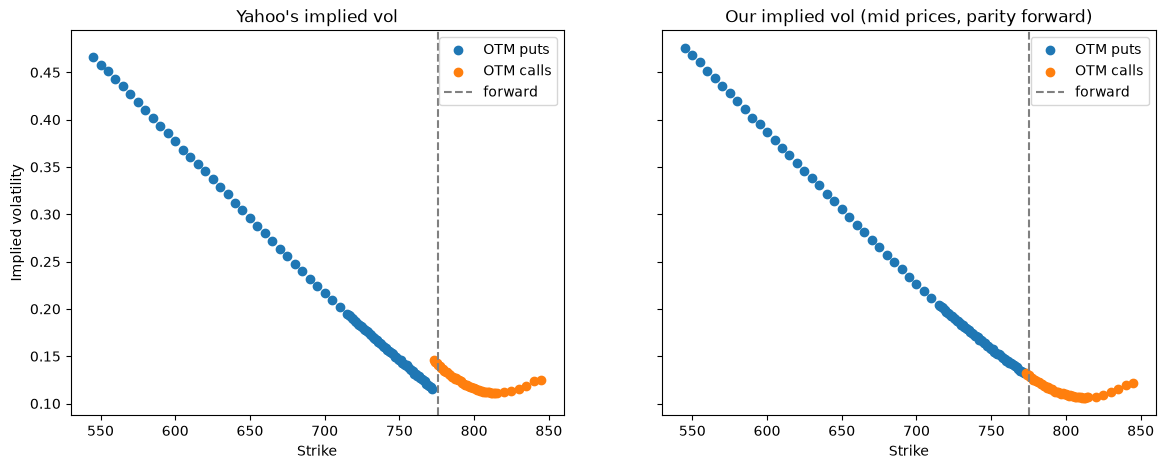

,type,strike,mid,impliedVolatility,iv
651,put,771.0,9.420,0.117379,0.133305
652,put,772.0,9.750,0.115503,0.131907
512,call,773.0,12.780,0.146066,0.131976
513,call,774.0,12.055,0.143395,0.129607
514,call,775.0,11.560,0.143060,0.129735
515,call,776.0,10.920,0.141000,0.128034
516,call,777.0,10.315,0.139123,0.126573
517,call,778.0,9.720,0.137307,0.125059
518,call,779.0,9.230,0.136376,0.124584
519,call,780.0,8.685,0.134805,0.123299


In [29]:
pick = pd.Timestamp("2026-11-06")
one = options[options["expiry"] == pick]
puts = one[one["type"] == "put"]
calls = one[one["type"] == "call"]
F_pick = one["F"].iloc[0]

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
left.scatter(puts["strike"], puts["impliedVolatility"], label="OTM puts")
left.scatter(calls["strike"], calls["impliedVolatility"], label="OTM calls")
left.set_title("Yahoo's implied vol")
right.scatter(puts["strike"], puts["iv"], label="OTM puts")
right.scatter(calls["strike"], calls["iv"], label="OTM calls")
right.set_title("Our implied vol (mid prices, parity forward)")
for ax in (left, right):
    ax.axvline(F_pick, color="grey", linestyle="--", label="forward")
    ax.set_xlabel("Strike")
    ax.legend()
left.set_ylabel("Implied volatility")
plt.show()

# strikes within $5 of the forward: does the put/call jump disappear?
near = one[(one["strike"] >= F_pick - 5) & (one["strike"] <= F_pick + 5)]
near[["type", "strike", "mid", "impliedVolatility", "iv"]].sort_values("strike")

The jump at the money is gone. Yahoo goes from 11.55% for the 772 put to 14.61% for the 773 call; mine goes from 13.19% to 13.20%. Put-call parity says a put and a call at the same strike must have the same implied vol, and now they do.

In [30]:
options.to_csv("spy_iv_2026-10-08.csv", index=False)
parity.to_csv("spy_forwards_2026-10-08.csv", index=False)  # notebooks 3 and 4 reuse the same forwards
print("Saved spy_iv_2026-10-08.csv and spy_forwards_2026-10-08.csv")

Saved spy_iv_2026-10-08.csv and spy_forwards_2026-10-08.csv
